# Summary — three ways to manufacture a beautiful backtest

This notebook pulls the three pitfalls together, with one chart style and one table.

| Pitfall | What leaks from the future | Notebook |
|---|---|---|
| Look-ahead bias | the return of the day you're trading | `02_lookahead.ipynb` |
| Survivorship bias | which companies will still exist | `03_survivorship.ipynb` |
| Overfitting / parameter mining | which parameters will turn out best | `04_overfitting.ipynb` |

All three are the same mistake in different places: **a decision in the backtest uses information
that wasn't available when the decision would have been made.**

The numbers here are recomputed from scratch by `src/pitfalls.py`, using the same data, parameters
and engine as the detailed notebooks. The charts come from `src/plots.py`. In every chart:

- **orange** is the cheat, the result the bug produces;
- **blue** is the honest version of the same strategy;
- **dashed grey** is buy-and-hold, where there's a natural benchmark;
- the **shaded area** between orange and blue is the illusion.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

sys.path.insert(0, str(Path.cwd().parent / "src"))
from pitfalls import PITFALLS, summary_table
from plots import plot_pitfall, format_summary, save_all

plt.rcParams["figure.dpi"] = 100
results = {key: build() for key, build in PITFALLS.items()}

---
## 1. Look-ahead bias

A 1-day momentum signal on SPY, run with `lag=0`: the position decided at today's close is paid
today's return, which it already knows. The equity curve can't go down. With `lag=1`, the
honest setting, the same signal has no edge at all.

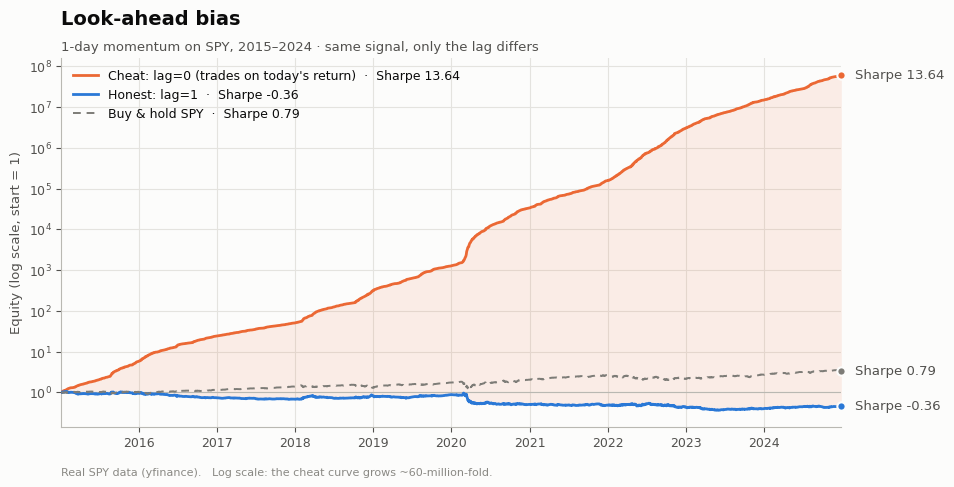

In [2]:
plot_pitfall(results["lookahead"]);

---
## 2. Survivorship bias

An equal-weight buy-and-hold portfolio on a synthetic universe of 200 stocks, 47 of which go
bankrupt. The cheat builds the portfolio from the stocks still listed at the *end*. The honest
version uses every stock that was listed at the *start*. The gap opens as companies drop out, and
it's widest during the market's slump, which is when bankruptcies cluster.

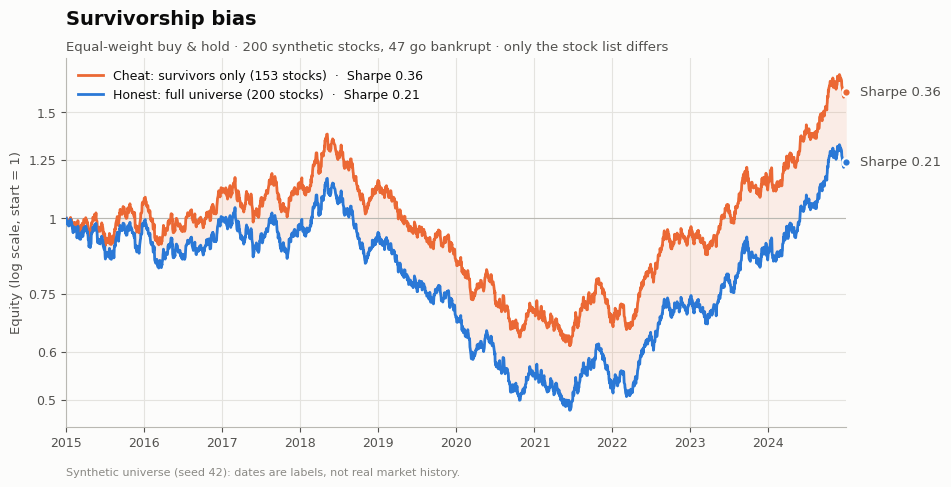

In [3]:
plot_pitfall(results["survivorship"]);

---
## 3. Overfitting / parameter mining

A moving-average trend filter on SPY. The cheat is the best of 499 (fast, slow) pairs, chosen
using the full 2005–2024 history. The honest version applies the same selection rule
walk-forward: each year it picks the best pair from the five years before, then trades it. All
three curves cover the same 2010–2024 window.

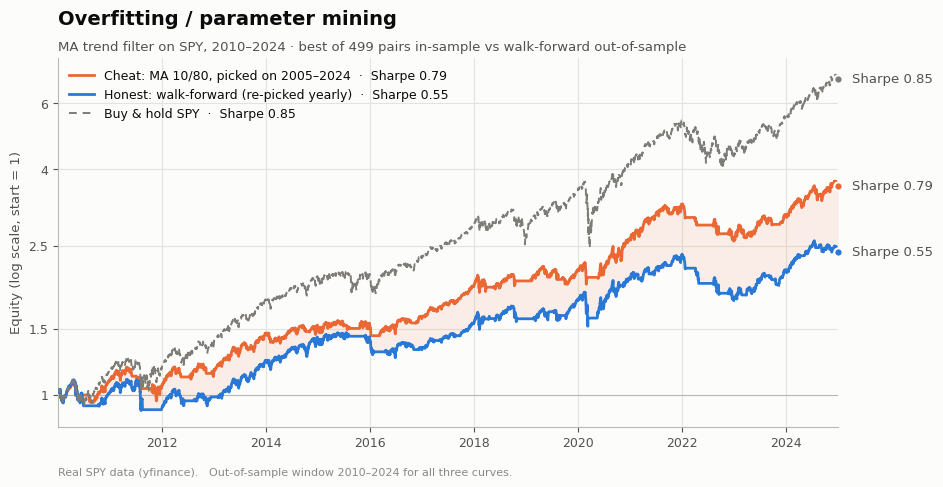

In [4]:
plot_pitfall(results["overfitting"]);

---
## Summary table

For each pitfall: the cheat's metrics, the honest metrics, and the **gap (honest − cheat)**.
Negative gaps are the part of the result that only existed because of the bug.

In [5]:
summary = summary_table(list(results.values()))
format_summary(summary)

### Reading the table

- **The size of the gap and how visible the bug is are unrelated.**
  Look-ahead bias produces a Sharpe gap of about 14. Nobody would believe that number, so it gets
  caught. The other two produce gaps of 0.15–0.25 Sharpe, roughly the difference between a
  mediocre strategy and a fundable one. Those are the bugs that make it into decisions.
- **Drawdown is part of the sales pitch.** The look-ahead cheat never draws down at all, and the
  overfit trend filter looks like it caps losses at about −20%. In every row the honest version
  draws down deeper.
- **No honest result beats doing nothing.** In both real-data cases the honest strategy has a
  lower Sharpe than simply holding SPY (see the benchmark table below). In the synthetic case
  there's no benchmark, but the honest return is less than half of what the survivors-only version
  reports.

### Benchmarks where they exist

In [6]:
pd.concat({r.title: r.metrics() for r in results.values()}).style.format(
    {"Sharpe": "{:.2f}", "CAGR": "{:.1%}", "MaxDrawdown": "{:.1%}"})

---
## Export

`save_all` writes every chart in two themes to `figures/`:

- `<pitfall>_light.png` for white pages (a PS, a paper, light slides),
- `<pitfall>_dark.png` for dark slide templates.

Both use the same colour roles. The dark versions use slightly adjusted steps so lines and text
stay legible on a dark background, rather than just inverting the light colours.

In [7]:
for p in save_all(list(results.values())):
    print(p.relative_to(Path.cwd().parent))

figures\lookahead_light.png
figures\lookahead_dark.png
figures\survivorship_light.png
figures\survivorship_dark.png
figures\overfitting_light.png
figures\overfitting_dark.png


---
## Interactive version

`app.py` at the project root shows the same charts and tables in a small Streamlit page, with a
drop-down to switch between pitfalls:

```bash
pip install -r requirements.txt
streamlit run app.py
```